# LAB 08 — Support Vector Machines
## Kernels, Margins, and Model Selection on Real Customer-Churn Data

## Student Information
- **Name:** Yasir Ali
- **Student ID:** 023-24-0215
- **Section:** G
- **GitHub:** https://github.com/faaniyasirr/ML-Labs
- **Kaggle:** https://www.kaggle.com/yasirali110/
- **Dataset:** Telco Customer Churn (Kaggle)
- **Dataset Source:** https://www.kaggle.com/datasets/blastchar/telco-customer-churn

---

### Before You Start
- You already studied SVM theory in class (margin, support vectors, kernel trick, C, gamma). This notebook does **not** re-teach that theory.
- This is **not** a "load data → `SVC().fit()` → done" lab. Most marks come from experimentation, visualization and justification, not from the fact that a model trained.
- You already know Python, Pandas, Matplotlib, `train_test_split`, encoding and evaluation metrics from Labs 2-6.
- Each task gives an **objective** and a **question** — not a code recipe. Every plot is followed by a written interpretation.

> **Setup note:** I use `random_state=42` and `test_size=0.20` (stratified) for every split and model, the same split used across the lab so that all models are compared fairly. All numbers quoted in the written answers come from the outputs printed in this notebook.


---

## Part 0 — Recap and Setup

Reload the Telco Customer Churn dataset and reapply the **same** cleaning/encoding pipeline from Labs 2/3/4/6:
- Convert `TotalCharges` to numeric and handle missing values
- Drop `customerID`
- Map `Churn` to 0/1
- One-hot encode categorical columns (`drop_first=True`)
- `train_test_split` with `stratify=y` — use the **same `random_state`** you used in Labs 3/4/6 so results stay comparable


In [1]:
import os, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.decomposition import PCA
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay, roc_curve,
                             roc_auc_score, precision_recall_curve, average_precision_score, classification_report)

RANDOM_STATE = 42   # same random_state / test_size as Labs 3/4/6 so results stay comparable
TEST_SIZE = 0.20
sns.set_style("whitegrid")

# --- Load the Telco Customer Churn dataset ---
# In Colab: upload "WA_Fn-UseC_-Telco-Customer-Churn.csv" (Kaggle) to the session, or let the fallback download a mirror of the same data.
local_names = ["WA_Fn-UseC_-Telco-Customer-Churn.csv", "Telco-Customer-Churn.csv"]
path = next((p for p in local_names if os.path.exists(p)), None)
if path is None:
    path = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"
df = pd.read_csv(path)
print("Shape:", df.shape)

# --- Same cleaning pipeline as Labs 2/3/4/6 ---
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")   # blanks -> NaN
print("Missing TotalCharges:", df["TotalCharges"].isna().sum())
df["TotalCharges"] = df["TotalCharges"].fillna(df["TotalCharges"].median())  # (these are tenure=0 customers)
df = df.drop(columns=["customerID"])
df["Churn"] = df["Churn"].map({"No": 0, "Yes": 1})
print(df["Churn"].value_counts(normalize=True).round(3).to_dict())
df.head()

Shape: (7043, 21)
Missing TotalCharges: 11
{0: 0.735, 1: 0.265}


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,0
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,0
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,1
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,0
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,1


In [2]:
cat_cols = df.select_dtypes(include=["object", "string"]).columns.tolist()
df_enc = pd.get_dummies(df, columns=cat_cols, drop_first=True, dtype=int)

X = df_enc.drop(columns=["Churn"])
y = df_enc["Churn"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, random_state=RANDOM_STATE, stratify=y)

print("Features:", X.shape[1])
print("Train:", X_train.shape, " Test:", X_test.shape)
print("Churn rate  train: %.3f | test: %.3f" % (y_train.mean(), y_test.mean()))

# helper used throughout the lab
def evaluate(model, Xte, yte, name=""):
    p = model.predict(Xte)
    return {"Model": name, "Accuracy": accuracy_score(yte, p), "Precision": precision_score(yte, p),
            "Recall": recall_score(yte, p), "F1": f1_score(yte, p)}

Features: 30
Train: (5634, 30)  Test: (1409, 30)
Churn rate  train: 0.265 | test: 0.265


---

## Part 1 — Why Scaling Matters for SVM

**Task 1.1 — Objective:** Demonstrate what happens to an SVM when features are not scaled.

**What to do:**
1. Train a linear-kernel SVM (`SVC(kernel='linear')`) directly on your **un-scaled** encoded features.
2. Train a second linear-kernel SVM on the same split after applying `StandardScaler` (fit on train only, transform on train and test).
3. Compare accuracy, F1-score, training time, and any convergence warnings between the two runs.

```python
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler

# unscaled
svm_raw = SVC(kernel='linear', random_state=42)
svm_raw.fit(X_train, y_train)

# scaled  (fit_transform on TRAIN, transform ONLY on TEST)
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s  = scaler.transform(X_test)
```


In [3]:
# Cap iterations so the unscaled run is bounded (max_iter=-1 would never warn and could run for a very long time)
MAX_ITER = 200_000
with warnings.catch_warnings(record=True) as w_raw:
    warnings.simplefilter("always")
    t0 = time.time()
    svm_raw = SVC(kernel="linear", random_state=RANDOM_STATE, max_iter=MAX_ITER)
    svm_raw.fit(X_train, y_train)
    t_raw = time.time() - t0
res_raw = evaluate(svm_raw, X_test, y_test, "Linear SVM (unscaled)")
print(res_raw)
print("Train time: %.2fs | support vectors: %d | warnings: %s" %
      (t_raw, svm_raw.support_.shape[0], [str(w.category.__name__) for w in w_raw] or "none"))
print("Feature ranges (unscaled): MonthlyCharges %.0f-%.0f, TotalCharges %.0f-%.0f, dummy columns 0-1" %
      (X_train.MonthlyCharges.min(), X_train.MonthlyCharges.max(), X_train.TotalCharges.min(), X_train.TotalCharges.max()))

{'Model': 'Linear SVM (unscaled)', 'Accuracy': 0.45564229950319374, 'Precision': 0.19152276295133439, 'Recall': 0.32620320855614976, 'F1': 0.2413452027695351}
Train time: 4.67s | support vectors: 1009 | warnings: ['ConvergenceWarning']
Feature ranges (unscaled): MonthlyCharges 18-119, TotalCharges 19-8685, dummy columns 0-1


In [4]:
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)   # fit on TRAIN only
X_test_s = scaler.transform(X_test)         # transform only on test (no leakage)

with warnings.catch_warnings(record=True) as w_s:
    warnings.simplefilter("always")
    t0 = time.time()
    svm_scaled = SVC(kernel="linear", random_state=RANDOM_STATE, max_iter=MAX_ITER)
    svm_scaled.fit(X_train_s, y_train)
    t_s = time.time() - t0
res_s = evaluate(svm_scaled, X_test_s, y_test, "Linear SVM (scaled)")
print("Train time: %.2fs | support vectors: %d | warnings: %s" %
      (t_s, svm_scaled.support_.shape[0], [str(w.category.__name__) for w in w_s] or "none"))

scale_cmp = pd.DataFrame([res_raw, res_s]).set_index("Model")
scale_cmp["Train time (s)"] = [t_raw, t_s]
scale_cmp["Support vectors"] = [svm_raw.support_.shape[0], svm_scaled.support_.shape[0]]
scale_cmp.round(4)

Train time: 1.18s | support vectors: 2569 | warnings: none


,Accuracy,Precision,Recall,F1,Train time (s),Support vectors
Model,,,,,,
Linear SVM (unscaled),0.4556,0.1915,0.3262,0.2413,4.6737,1009
Linear SVM (scaled),0.7892,0.6207,0.5294,0.5714,1.1797,2569


**Questions to answer:**

**(a) What differences did you observe between the unscaled and scaled models (accuracy, warnings, training time)?**

The difference is large. The unscaled linear SVM reached only **45.6 % accuracy** (precision 0.192, recall 0.326, **F1 0.241**) — that is *worse than a model that predicts "stay" for everybody* (≈73.5 % accuracy, because 26.5 % of customers churn). It also raised a **`ConvergenceWarning`**: it hit the iteration cap (`max_iter=200,000`) without converging, and took **≈ 4.5 s** (4.67 s in the saved run). The scaled model reached **78.9 % accuracy** (precision 0.621, recall 0.529, **F1 0.571**), raised **no warning**, and trained in **≈ 1 s** (about 4× faster, even though the unscaled run was cut off early — without a cap it would have run longer). Interestingly the unscaled model had far *fewer* support vectors (1,009 vs 2,569), which is a symptom of a degenerate solution, not a better one.

**(b) Why does an unscaled linear SVM behave this way, in terms of how the margin/decision boundary is computed?**

A linear SVM looks for a hyperplane `w·x + b = 0` that maximizes the margin `2/‖w‖` while penalizing violations with `C·Σξ`. Both the margin and the decision value are computed from dot products/distances, so a feature with a huge numeric range dominates them. Here `TotalCharges` ranges from ~19 to ~8,685 and `MonthlyCharges` from 18 to 119, while the one-hot columns only take values 0 or 1. A change of 1 in a dummy column is negligible next to changes of hundreds or thousands in `TotalCharges`, so the geometry is almost entirely determined by the two charge columns. To let a 0/1 feature (e.g. contract type) matter, `w` would need a very large coefficient for it, but `‖w‖²` is exactly what the SVM is trying to keep small, so the optimizer is pulled in conflicting directions. The problem is also badly conditioned, which is why the solver crawled and failed to converge. After `StandardScaler` every feature has mean 0 and std 1, so each one contributes comparably to the margin.

**(c) From this point onward in the lab, which version will you use for every subsequent SVM, and why?**

The **scaled** version (`X_train_s` / `X_test_s`, scaler fitted on the training set only) for every SVM, including the PCA, grid search and class-weight experiments. It is dramatically more accurate (F1 0.571 vs 0.241), converges, is faster, and fitting the scaler on train only avoids data leakage.

---

## Part 2 — Kernel Comparison

**Task 2.1 — Objective:** Train and fairly compare SVM classifiers using the linear, RBF and polynomial kernels on your **scaled** features.

**What to do:**
1. Train three `SVC` models — `kernel='linear'`, `kernel='rbf'`, `kernel='poly'` — with the same `random_state`, on the same scaled train split.
2. For each, record: Accuracy, Precision, Recall, F1-score, and number of support vectors (`model.support_.shape[0]`).
3. Assemble a single comparison table (a DataFrame is fine).
4. Plot the confusion matrix for whichever kernel performed best on F1-score.

| Syntax | Description |
|---|---|
| `SVC(kernel=...)` | `'linear'`, `'rbf'`, or `'poly'` |
| `model.support_` | indices of support vectors |
| `model.n_support_` | number of support vectors per class |


In [5]:
kernel_models, rows = {}, []
for k in ["linear", "rbf", "poly"]:
    t0 = time.time()
    m = SVC(kernel=k, random_state=RANDOM_STATE)
    m.fit(X_train_s, y_train)
    fit_t = time.time() - t0
    kernel_models[k] = m
    r = evaluate(m, X_test_s, y_test, k)
    r["Support vectors"] = m.support_.shape[0]
    r["SV per class (0/1)"] = tuple(m.n_support_)
    r["Fit time (s)"] = fit_t
    rows.append(r)

In [6]:
kernel_cmp = pd.DataFrame(rows).set_index("Model")
kernel_cmp.round(4)

,Accuracy,Precision,Recall,F1,Support vectors,SV per class (0/1),Fit time (s)
Model,,,,,,,
linear,0.7892,0.6207,0.5294,0.5714,2569,"(1287, 1282)",0.9988
rbf,0.7928,0.6444,0.4893,0.5562,2661,"(1432, 1229)",0.7419
poly,0.7892,0.6421,0.4652,0.5395,2739,"(1485, 1254)",0.8946


Best kernel by F1: linear


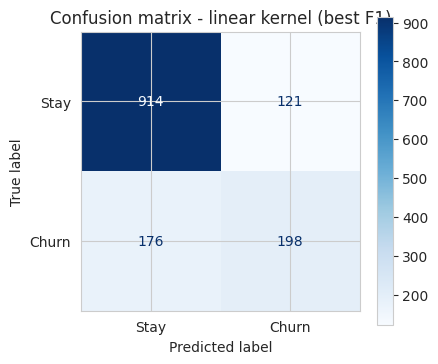

In [7]:
best_k = kernel_cmp["F1"].idxmax()
print("Best kernel by F1:", best_k)
fig, ax = plt.subplots(figsize=(4.5, 4))
ConfusionMatrixDisplay.from_estimator(kernel_models[best_k], X_test_s, y_test,
                                      display_labels=["Stay", "Churn"], cmap="Blues", ax=ax)
ax.set_title(f"Confusion matrix - {best_k} kernel (best F1)")
plt.show()

**Interpretation of the confusion matrix:** The best-F1 kernel (linear) correctly identifies about half of the churners (true positives in the bottom-right cell) but still misses a large share of them (bottom-left cell, false negatives). The top-left cell (correctly retained customers) dominates simply because loyal customers are ~73 % of the data. So even the best default kernel is better at recognising loyal customers than churners — the imbalance problem we address in Part 5.

**Questions to answer:**

**(a) Which kernel produced the best F1-score on the test set? Does this surprise you given the theory covered in class?**

The **linear** kernel gave the best F1 (**0.571**), ahead of RBF (0.556) and polynomial (0.540). Accuracy is nearly identical for all three (0.789–0.793). This is mildly surprising: theory suggests RBF is the more flexible kernel and often wins. However, after one-hot encoding the data has 30 features and the churn signal is largely additive (contract type, tenure, internet service, charges), so a linear boundary already captures most of it, and extra flexibility mainly adds variance. Note also that the gaps (≈0.015 F1) are small relative to test-set noise (only 374 churners), so the honest conclusion is "the kernels are close, and linear is not worse."

**(b) Which kernel used the most support vectors, and what does a high support-vector count suggest about the complexity of the decision boundary it learned?**

**Polynomial** used the most (**2,739**), followed by RBF (2,661) and linear (2,569). All three use roughly **46–49 % of the 5,634 training points** as support vectors, which signals that the two classes overlap heavily: a very large fraction of points lie inside the margin or on the wrong side of it. More support vectors for the non-linear kernels also means their boundaries depend on more individual points (more complex/less sparse), without buying better performance.

**(c) Based on this evidence, which kernel would you carry forward for hyperparameter tuning in Part 4? Justify with numbers.**

I carry **RBF** forward. Justification: (1) the three kernels are within 0.016 F1 of each other, so the untuned ranking is not decisive; (2) RBF has the highest precision (0.644 vs 0.621 linear) and the best accuracy (0.793); (3) the linear kernel has no `gamma` and only `C` to tune, whereas RBF has two hyperparameters (C, gamma) that can change its behaviour a lot (the default `C=1, gamma='scale'` is just one point in that space), so it has the most room to improve through tuning, and Part 4 explicitly requires the C × gamma search. I note honestly that linear is the best *untuned* kernel, and I will check in Part 4 whether tuning RBF actually beats it (it does not — see 4(d)).

---

## Part 3 — Visualizing the Margin: What Does C Actually Do?

**Task 3.1 — Objective:** Reduce your scaled features to 2 dimensions and visualize how an RBF-kernel SVM's decision boundary changes as C increases.

**What to do:**
1. Use `PCA(n_components=2)` on your scaled training features. Report the total explained variance ratio of the two components.
2. Train three RBF-kernel SVMs on this 2-D projection using a small, medium and large C (choose 3 values spanning at least two orders of magnitude, e.g. 0.01, 1, 100).
3. For each C, plot the 2-D decision boundary (mesh grid + `contourf`) with training points overlaid, and report the number of support vectors.

**Hint — Building the Mesh Grid:**
- Build a fine grid of (x, y) spanning slightly beyond your projected data's min/max using `np.meshgrid`.
- Call `model.predict()` on every grid point (flatten, then reshape back to grid shape).
- `plt.contourf(xx, yy, Z, alpha=0.3)` draws shaded regions; `plt.scatter(...)` overlays real points colored by true label.


In [8]:
pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_train_2d = pca.fit_transform(X_train_s)
X_test_2d = pca.transform(X_test_s)
print("Explained variance ratio per component:", pca.explained_variance_ratio_.round(4))
print("Total explained variance (2 components): %.1f%%" % (100 * pca.explained_variance_ratio_.sum()))

Explained variance ratio per component: [0.3325 0.1198]
Total explained variance (2 components): 45.2%


In [9]:
C_values = [0.01, 1, 100]
models_2d = {}
for c in C_values:
    m = SVC(kernel="rbf", C=c, gamma="scale", random_state=RANDOM_STATE)
    m.fit(X_train_2d, y_train)
    models_2d[c] = m
    print("C=%-6s | support vectors: %4d | train acc: %.3f | test acc: %.3f | test F1: %.3f" % (
        c, m.support_.shape[0], m.score(X_train_2d, y_train), m.score(X_test_2d, y_test),
        f1_score(y_test, m.predict(X_test_2d))))

C=0.01   | support vectors: 2997 | train acc: 0.735 | test acc: 0.735 | test F1: 0.000


C=1      | support vectors: 2659 | train acc: 0.779 | test acc: 0.779 | test F1: 0.477


C=100    | support vectors: 2631 | train acc: 0.781 | test acc: 0.779 | test F1: 0.472


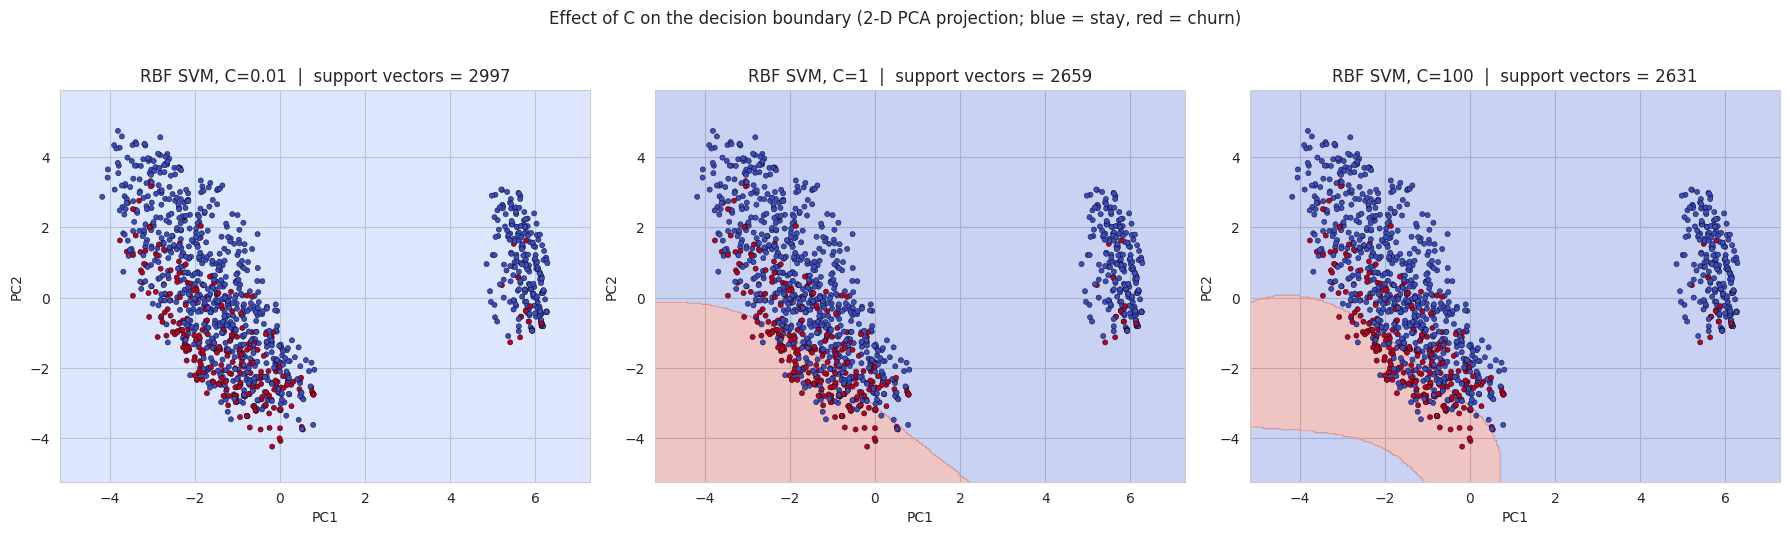

In [10]:
x_min, x_max = X_train_2d[:, 0].min() - 1, X_train_2d[:, 0].max() + 1
y_min, y_max = X_train_2d[:, 1].min() - 1, X_train_2d[:, 1].max() + 1
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 300), np.linspace(y_min, y_max, 300))
grid = np.c_[xx.ravel(), yy.ravel()]

# subsample points for readability (boundary is still computed from the full model)
rng = np.random.RandomState(RANDOM_STATE)
idx = rng.choice(len(X_train_2d), 1200, replace=False)

fig, axes = plt.subplots(1, 3, figsize=(18, 5.2))
for ax, c in zip(axes, C_values):
    m = models_2d[c]
    Z = m.predict(grid).reshape(xx.shape)
    ax.contourf(xx, yy, Z, alpha=0.3, cmap="coolwarm")
    ax.scatter(X_train_2d[idx, 0], X_train_2d[idx, 1], c=y_train.values[idx], cmap="coolwarm",
               edgecolor="k", s=14, linewidth=0.3)
    ax.set_title(f"RBF SVM, C={c}  |  support vectors = {m.support_.shape[0]}")
    ax.set_xlabel("PC1"); ax.set_ylabel("PC2")
plt.suptitle("Effect of C on the decision boundary (2-D PCA projection; blue = stay, red = churn)", y=1.02)
plt.tight_layout(); plt.show()

**Interpretation of the plots:** With **C = 0.01** the whole plane is shaded as "stay" — the SVM is so heavily regularized that it ignores the red churn points entirely and just predicts the majority class (test F1 = 0.0, accuracy 0.735 = the base rate). With **C = 1** a smooth curved "churn" region appears in the lower-left, where the red points are concentrated. With **C = 100** the churn region is larger and its edge is more flexible (an extra curved lobe appears at the bottom-left), because the model now pays a high price for each misclassified red point. The red and blue points overlap heavily everywhere, so even C = 100 cannot separate them cleanly in 2-D.

**Questions to answer:**

**(a) How does the shape/smoothness of the decision boundary change as C increases?**

At **C = 0.01** there is *no* boundary at all (single class everywhere) — maximally smooth/over-regularized. At **C = 1** the boundary is a single smooth, gently curved edge. At **C = 100** the boundary is more flexible and bends more to include red points (larger churn region with an additional curved lobe). So as C increases the boundary goes from non-existent → smooth → more complex and tightly fitted to the training points.

**(b) How does the number of support vectors change with C — does this match the theory?**

It decreases: **2,997 (C=0.01) → 2,659 (C=1) → 2,631 (C=100)**. This matches the theory: a small C allows a wide, soft margin where many points violate or sit inside the margin, and every such point becomes a support vector; a large C penalizes violations strongly, so the margin narrows and fewer points remain inside it. The decrease from C=1 to C=100 is small, because in this 2-D projection the classes overlap so much that most points stay margin violators no matter how large C is.

**(c) Which C looks like it is overfitting on this 2-D view, and which looks like it is underfitting? Explain the visual evidence.**

**C = 0.01 is underfitting**: the boundary does not exist, the model predicts "stay" everywhere, train accuracy (0.735) equals the base rate and F1 is 0. **C = 100 is the one closest to overfitting**: it has the most contorted boundary, wrapping around local clusters of red points (the extra lobe at the bottom-left). However, the evidence for *serious* overfitting is weak: train accuracy 0.781 vs test accuracy 0.779 (no real gap) and test F1 is practically unchanged versus C = 1 (0.472 vs 0.477). **C = 1** looks like the best balance.

**(d) Why is this 2-D plot only an APPROXIMATE illustration of what the real (high-dimensional) SVM is doing? What could it be misleading you about?**

The two principal components retain only **45.2 %** of the variance (PC1 33.3 % + PC2 12.0 %), so more than half of the information is thrown away. PCA is unsupervised: it keeps directions of largest variance, not directions that separate churners from non-churners, so classes that overlap in this view may be well separated in the full 30-D space (the real SVM reaches F1 ≈ 0.56 versus ≈ 0.47 here). The plot can therefore mislead us about (i) how separable the classes really are, (ii) how complex the true boundary is, (iii) the support-vector counts and the real effect of C and gamma, which differ in the full feature space. It is an intuition aid, not a picture of the actual model.

---

## Part 4 — Systematic Hyperparameter Search

**Task 4.1 — Objective:** Run `GridSearchCV` over a C x gamma grid for an RBF-kernel SVM and select the best configuration using cross-validated F1-score.

**What to do:**
1. Define a parameter grid with at least 3 values of C and at least 3 values of gamma.
2. Run `GridSearchCV(SVC(kernel='rbf'), param_grid, cv=5, scoring='f1')` on your scaled **training** data.
3. Extract `gs.cv_results_` and reshape the mean test scores into a C x gamma grid.
4. Visualize as a heatmap (`imshow` or a pivoted DataFrame) with C and gamma labeled.
5. Refit the best estimator and report its performance on the held-out **test** set.

| Syntax | Description |
|---|---|
| `GridSearchCV(estimator, param_grid, cv, scoring)` | tries every combination via k-fold CV |
| `gs.best_params_` | best hyperparameter combination |
| `gs.cv_results_['mean_test_score']` | mean CV score per combination |


In [11]:
param_grid = {"C": [0.1, 1, 10, 100],
              "gamma": [0.0001, 0.001, 0.01, 0.1]}
gs = GridSearchCV(SVC(kernel="rbf", random_state=RANDOM_STATE), param_grid, cv=5, scoring="f1", n_jobs=-1)
t0 = time.time()
gs.fit(X_train_s, y_train)
print("Grid search time: %.1fs (%d combinations x 5 folds)" % (time.time() - t0, len(gs.cv_results_["params"])))
print("Best params:", gs.best_params_)
print("Best CV F1: %.4f" % gs.best_score_)

Grid search time: 59.3s (16 combinations x 5 folds)
Best params: {'C': 100, 'gamma': 0.01}
Best CV F1: 0.5877


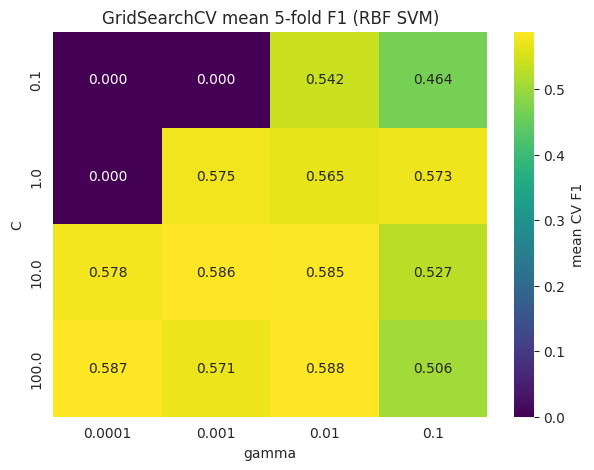

gamma,0.0001,0.0010,0.0100,0.1000
C,,,,
0.1,0.0000,0.0000,0.5417,0.4640
1.0,0.0000,0.5746,0.5650,0.5734
10.0,0.5777,0.5857,0.5853,0.5266
100.0,0.5870,0.5710,0.5877,0.5060


In [12]:
scores = gs.cv_results_["mean_test_score"].reshape(len(param_grid["C"]), len(param_grid["gamma"]))
heat = pd.DataFrame(scores, index=param_grid["C"], columns=param_grid["gamma"])
heat.index.name, heat.columns.name = "C", "gamma"

plt.figure(figsize=(7, 5))
sns.heatmap(heat, annot=True, fmt=".3f", cmap="viridis", cbar_kws={"label": "mean CV F1"})
plt.title("GridSearchCV mean 5-fold F1 (RBF SVM)")
plt.show()
heat.round(4)

**Interpretation of the heatmap:** Bright (high-F1) cells form a broad band: C ≥ 10 combined with gamma between 0.001 and 0.01 (all ≈ 0.57–0.59), plus C = 1 with gamma 0.001–0.1. The cells with **F1 = 0.000** (C ≤ 1 with the smallest gammas, and C = 0.1 with gamma ≤ 0.001) are *underfitting*: the model is so smooth/regularized that it predicts only "stay", so it finds no churners. The score also drops at gamma = 0.1 with large C (0.506 at C = 100) — a too-flexible, overfitting corner.

               Accuracy  Precision  Recall      F1
Model                                             
Tuned RBF SVM    0.7786     0.5939  0.5241  0.5568
CV F1 = 0.5877  vs  test F1 = 0.5568  (gap = 0.0309)
Untuned RBF (Part 2) test F1 = 0.5562


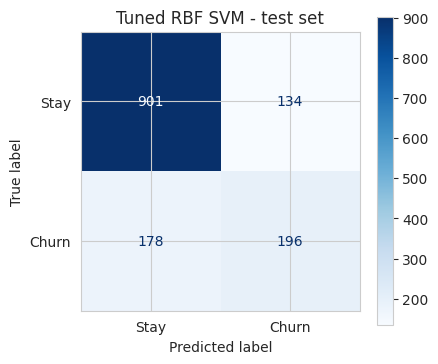


Un-tuned vs tuned RBF:


,Accuracy,Precision,Recall,F1
Model,,,,
"RBF default (C=1, gamma='scale')",0.7928,0.6444,0.4893,0.5562
Tuned RBF SVM,0.7786,0.5939,0.5241,0.5568


In [13]:
best_svm = gs.best_estimator_
res_best = evaluate(best_svm, X_test_s, y_test, "Tuned RBF SVM")
print(pd.DataFrame([res_best]).set_index("Model").round(4))
print("CV F1 = %.4f  vs  test F1 = %.4f  (gap = %.4f)" % (gs.best_score_, res_best["F1"], gs.best_score_ - res_best["F1"]))
print("Untuned RBF (Part 2) test F1 = %.4f" % kernel_cmp.loc["rbf", "F1"])

fig, ax = plt.subplots(figsize=(4.5, 4))
ConfusionMatrixDisplay.from_estimator(best_svm, X_test_s, y_test, display_labels=["Stay", "Churn"], cmap="Blues", ax=ax)
ax.set_title("Tuned RBF SVM - test set")
plt.show()

print("\nUn-tuned vs tuned RBF:")
pd.DataFrame([evaluate(kernel_models["rbf"], X_test_s, y_test, "RBF default (C=1, gamma='scale')"), res_best]).set_index("Model").round(4)

**Interpretation of the confusion matrix / table:** The tuned model correctly flags about half of the churners (recall 0.524) with moderate precision (0.594). The table shows tuning changed the precision/recall balance slightly but left the F1 essentially unchanged versus the default RBF model.

**Questions to answer:**

**(a) What were the best C and gamma values found, and the corresponding cross-validated F1-score?**

**C = 100, gamma = 0.01**, with a mean 5-fold CV **F1 = 0.5877**.

**(b) Is there a clear "best region" in the heatmap, or do several combinations perform similarly?**

There is a broad plateau rather than a sharp peak: (C=100, γ=0.01) = 0.5877, (C=100, γ=0.0001) = 0.5870, (C=10, γ=0.001) = 0.5857, (C=10, γ=0.01) = 0.5853, (C=10, γ=0.0001) = 0.5777 — all within about 0.01 of each other, i.e. within the fold-to-fold noise, so the "best" combination is not meaningfully better than its neighbours. Along the diagonal where C and 1/gamma trade off against each other, many settings are equivalent. This tells us the model is **fairly robust to exact values** as long as it is not in the extreme underfit corner (small C and small gamma → F1 = 0) or the overfit corner (large gamma). So the exact "best" values matter much less than staying in the right region.

**(c) Did the cross-validated score and the final test-set score agree closely, or was there a gap? What would a large gap suggest?**

CV F1 = 0.5877 versus test F1 = 0.5568: a gap of **0.031**. That is small to moderate and expected: the CV score is the maximum over 16 candidate settings, so it is slightly optimistic (selection bias), and the test set contains only 374 churners, so its F1 has a standard error of a few hundredths. A *large* gap would suggest overfitting to the validation folds / the hyperparameter search, data leakage in the CV, or a train/test distribution mismatch.

**(d) Compare the tuned RBF model's test performance to the un-tuned RBF model from Part 2. Was tuning worth it?**

Test F1 is **0.5568 (tuned) vs 0.5562 (default)** — an improvement of 0.0006, i.e. nothing. Tuning shifted the trade-off slightly (recall 0.489 → 0.524, precision 0.644 → 0.594, accuracy 0.793 → 0.779) but did not improve the overall score. The grid search took ≈ 60 s versus < 1 s for a single fit. For the F1 metric, **tuning was not worth it here**; the default `C=1, gamma='scale'` was already in the plateau. The real improvement comes from handling class imbalance (Part 5), not from C/gamma.

---

## Part 5 — Class Imbalance and the Business Trade-off

**Task 5.1 — Objective:** Compare your best RBF-kernel SVM with and without `class_weight='balanced'`, and reason about which is more useful for the business.

**What to do:**
1. Using your best (C, gamma) from Part 4, train two RBF SVMs: `class_weight=None` and `class_weight='balanced'`.
2. Report Precision, Recall, F1-score and confusion matrix for both on the test set.
3. Plot an ROC curve or Precision-Recall curve for the balanced model.


In [14]:
bp = gs.best_params_
cw_models, cw_rows = {}, []
for cw in [None, "balanced"]:
    m = SVC(kernel="rbf", C=bp["C"], gamma=bp["gamma"], class_weight=cw, probability=True, random_state=RANDOM_STATE)
    m.fit(X_train_s, y_train)
    cw_models[str(cw)] = m
    cw_rows.append(evaluate(m, X_test_s, y_test, f"RBF class_weight={cw}"))
    print(f"class_weight={cw}  confusion matrix [[TN FP],[FN TP]]:\n", confusion_matrix(y_test, m.predict(X_test_s)))
cw_cmp = pd.DataFrame(cw_rows).set_index("Model")
cw_cmp.round(4)

class_weight=None  confusion matrix [[TN FP],[FN TP]]:
 [[901 134]
 [178 196]]


class_weight=balanced  confusion matrix [[TN FP],[FN TP]]:
 [[764 271]
 [ 86 288]]


,Accuracy,Precision,Recall,F1
Model,,,,
RBF class_weight=None,0.7786,0.5939,0.5241,0.5568
RBF class_weight=balanced,0.7466,0.5152,0.7701,0.6174


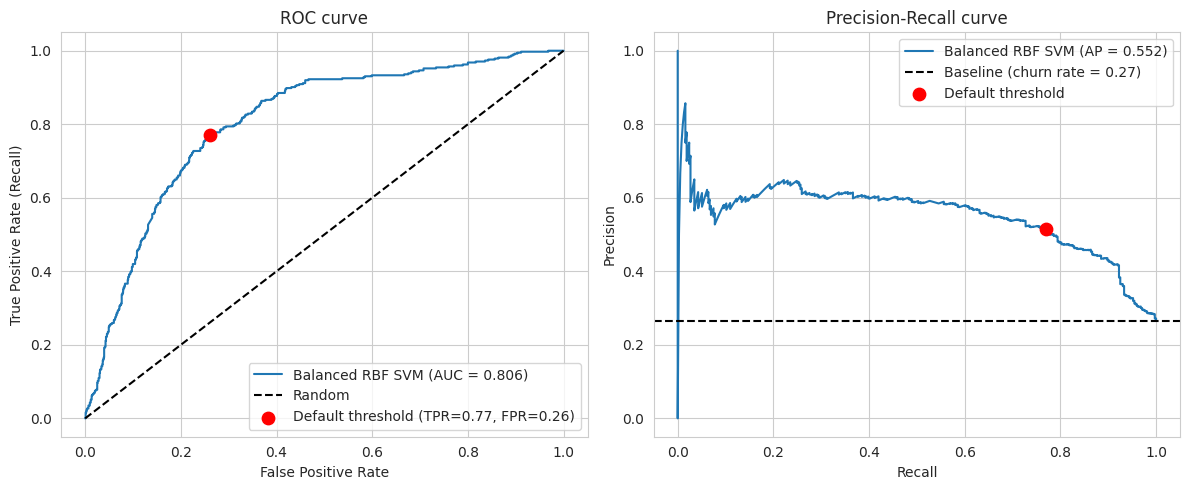

ROC-AUC (balanced): 0.8058 | ROC-AUC (unweighted): 0.7880


In [15]:
bal = cw_models["balanced"]
proba = bal.predict_proba(X_test_s)[:, 1]          # needs SVC(probability=True) -> Platt scaling + internal 5-fold CV
fpr, tpr, thr = roc_curve(y_test, proba)
auc = roc_auc_score(y_test, proba)
prec, rec, _ = precision_recall_curve(y_test, proba)
ap = average_precision_score(y_test, proba)

# operating point of the model's default decision rule (predict())
pred_bal = bal.predict(X_test_s)
tn, fp, fn, tp = confusion_matrix(y_test, pred_bal).ravel()
op_fpr, op_tpr = fp / (fp + tn), tp / (tp + fn)
op_prec = tp / (tp + fp)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].plot(fpr, tpr, label=f"Balanced RBF SVM (AUC = {auc:.3f})")
axes[0].plot([0, 1], [0, 1], "k--", label="Random")
axes[0].scatter(op_fpr, op_tpr, color="red", s=80, zorder=5, label=f"Default threshold (TPR={op_tpr:.2f}, FPR={op_fpr:.2f})")
axes[0].set(xlabel="False Positive Rate", ylabel="True Positive Rate (Recall)", title="ROC curve")
axes[0].legend(loc="lower right")
axes[1].plot(rec, prec, label=f"Balanced RBF SVM (AP = {ap:.3f})")
axes[1].axhline(y_test.mean(), color="k", ls="--", label=f"Baseline (churn rate = {y_test.mean():.2f})")
axes[1].scatter(op_tpr, op_prec, color="red", s=80, zorder=5, label="Default threshold")
axes[1].set(xlabel="Recall", ylabel="Precision", title="Precision-Recall curve")
axes[1].legend()
plt.tight_layout(); plt.show()
print("ROC-AUC (balanced): %.4f | ROC-AUC (unweighted): %.4f" % (auc, roc_auc_score(y_test, cw_models["None"].predict_proba(X_test_s)[:, 1])))

**Interpretation of the curves:** The ROC curve lies clearly above the diagonal (AUC = 0.806), showing the balanced model ranks churners above non-churners much better than chance. The red dot marks the model's default decision rule: it sits at a high true-positive rate (≈ 0.77) at the price of a false-positive rate of ≈ 0.26. On the precision–recall curve the model stays well above the baseline precision of 0.265 (the churn rate), and the default operating point corresponds to ≈ 0.77 recall with ≈ 0.52 precision. Sliding the threshold would move us along these curves to trade recall for precision. Balancing also improved the ranking quality (AUC 0.806 vs 0.788 without class weights).

**Questions to answer:**

**(a) Precisely how did precision and recall move when you switched to `class_weight='balanced'`? Give the numbers.**

| | Precision | Recall | F1 | Accuracy | FN | FP |
|---|---|---|---|---|---|---|
| `class_weight=None` | 0.594 | 0.524 | 0.557 | 0.779 | 178 | 134 |
| `class_weight='balanced'` | 0.515 | 0.770 | 0.617 | 0.747 | 86 | 271 |

Precision **fell by 0.079** (0.594 → 0.515), recall **rose by 0.246** (0.524 → 0.770), and F1 rose by 0.061. The balanced model catches **92 more churners** (false negatives 178 → 86) but wrongly flags **137 more loyal customers** (false positives 134 → 271).

**(b) Is it more costly to miss an actual churner (FN) or to wrongly flag a loyal customer (FP)? Which model would you recommend deploying?**

For a telecom company a **false negative is usually more costly**: a churner who is missed is lost revenue (and acquiring a replacement customer typically costs several times more than retaining one), while a false positive just means a retention offer (discount, call, upgrade) sent to someone who would have stayed anyway. From the numbers: switching to the balanced model buys 92 extra caught churners at the price of 137 extra wasted offers, so it pays off whenever a lost churner costs more than about **1.5×** the cost of one wasted offer (137/92 ≈ 1.5), which is a very plausible assumption. I would therefore deploy the **balanced** model. (Caveat: this depends on the real cost figures, which we do not have.)

**(c) How did you obtain probability-like scores for your ROC/PR curve, and what did you have to enable in `SVC()`?**

I set **`probability=True`** in `SVC(...)` and used `predict_proba(X_test_s)[:, 1]`. This makes scikit-learn fit a Platt-scaling (sigmoid) calibrator on the SVM's decision values using an internal 5-fold cross-validation, which makes training noticeably slower and means `predict_proba` can occasionally disagree with `predict`. The cheaper alternative is to use `decision_function()` scores directly, which also work for ROC/PR curves (I save both in Part 7).

---

## Part 6 — Model Showdown: SVM vs. Everything Else

**Task 6.1 — Objective:** Build a single comparison table across all five algorithms (Decision Tree, Random Forest, Logistic Regression, KNN, SVM) and select ONE final model for production.

**What to do:**
1. Build a table: one row per model, columns Accuracy / Precision / Recall / F1-score. Re-run earlier models here on the same split if you don't have saved numbers.
2. Produce ONE bar chart comparing F1-score across all five models.


In [16]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier

# Saved numbers from Labs 3/4/6 are not available here, so every model is re-run on THIS lab's split (fair comparison).
timing = {}
def timed_fit(name, model, Xtr, Xte):
    t0 = time.time(); model.fit(Xtr, y_train); timing[name] = time.time() - t0
    return evaluate(model, Xte, y_test, name)

results = []
results.append(timed_fit("Decision Tree", DecisionTreeClassifier(max_depth=5, random_state=RANDOM_STATE), X_train, X_test))

rf_gs = GridSearchCV(RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1),
                     {"n_estimators": [100, 300], "max_depth": [5, 10, None], "min_samples_leaf": [1, 5]},
                     cv=5, scoring="f1", n_jobs=-1)
t0 = time.time(); rf_gs.fit(X_train, y_train); timing["Random Forest (tuned)"] = time.time() - t0
results.append(evaluate(rf_gs.best_estimator_, X_test, y_test, "Random Forest (tuned)"))
print("RF best params:", rf_gs.best_params_)

results.append(timed_fit("Logistic Regression", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE), X_train_s, X_test_s))
results.append(timed_fit("KNN (k=11)", KNeighborsClassifier(n_neighbors=11), X_train_s, X_test_s))

# supplementary fairness check: Logistic Regression with the same class_weight trick (NOT one of the five required rows)
results.append(timed_fit("Logistic Regression (balanced) [extra]", LogisticRegression(max_iter=1000, class_weight="balanced", random_state=RANDOM_STATE), X_train_s, X_test_s))

# both tuned SVM variants from Part 5 are shown; the better one is the "best SVM"
for key, label in [("None", "SVM (tuned RBF)"), ("balanced", "SVM (tuned RBF, balanced)")]:
    t0 = time.time(); m = SVC(kernel="rbf", C=bp["C"], gamma=bp["gamma"], class_weight=None if key == "None" else "balanced",
                              random_state=RANDOM_STATE).fit(X_train_s, y_train); timing[label] = time.time() - t0
    results.append(evaluate(m, X_test_s, y_test, label))

showdown = pd.DataFrame(results).set_index("Model")
showdown["Train time (s)"] = pd.Series(timing)
showdown.round(4)

RF best params: {'max_depth': 10, 'min_samples_leaf': 5, 'n_estimators': 300}


,Accuracy,Precision,Recall,F1,Train time (s)
Model,,,,,
Decision Tree,0.7942,0.6296,0.5455,0.5845,0.0174
Random Forest (tuned),0.8034,0.6667,0.5187,0.5835,46.7512
Logistic Regression,0.8070,0.6584,0.5668,0.6092,0.0224
KNN (k=11),0.7743,0.5787,0.5508,0.5644,0.0022
Logistic Regression (balanced) [extra],0.7388,0.5052,0.7807,0.6134,0.0237
SVM (tuned RBF),0.7786,0.5939,0.5241,0.5568,2.1700
"SVM (tuned RBF, balanced)",0.7466,0.5152,0.7701,0.6174,2.3955


Best SVM variant used in the 5-model chart: SVM (tuned RBF, balanced)


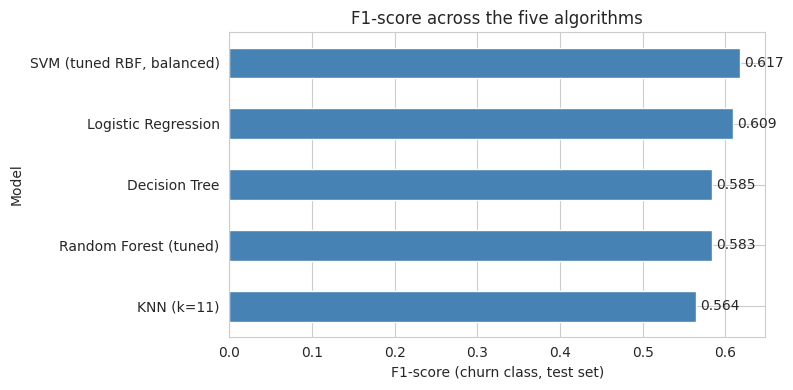

Best F1:  SVM (tuned RBF, balanced) | Best Recall: SVM (tuned RBF, balanced)


In [17]:
showdown_main = showdown.drop(index="Logistic Regression (balanced) [extra]")
five = showdown_main.drop(index="SVM (tuned RBF)" if showdown.loc["SVM (tuned RBF, balanced)", "F1"] >= showdown.loc["SVM (tuned RBF)", "F1"]
                    else "SVM (tuned RBF, balanced)")
print("Best SVM variant used in the 5-model chart:", five.index[-1])
ax = five["F1"].sort_values().plot.barh(figsize=(8, 4), color="steelblue")
for i, v in enumerate(five["F1"].sort_values()):
    ax.text(v + 0.005, i, f"{v:.3f}", va="center")
ax.set_xlabel("F1-score (churn class, test set)"); ax.set_title("F1-score across the five algorithms")
plt.tight_layout(); plt.show()
print("Best F1: ", five["F1"].idxmax(), "| Best Recall:", five["Recall"].idxmax())

**Interpretation of the bar chart:** The five F1-scores are tightly clustered between ≈ 0.56 and ≈ 0.62. The balanced SVM is on top, followed closely by Logistic Regression, while the un-weighted models (Decision Tree, Random Forest, KNN) sit around 0.56–0.58. The spread is small, so differences of ~0.01 should not be over-interpreted; the main visible jump is the one created by class weighting.

*Note:* Saved numbers from Labs 3/4/6 were not available, so Decision Tree (depth 5), tuned Random Forest (grid search), Logistic Regression and KNN (k = 11) were re-run on this lab's split. The table also contains both SVM variants and one extra row (Logistic Regression with `class_weight='balanced'`) as a fairness check; the bar chart uses the five required models with the best SVM variant.

**Questions to answer:**

**(a) Which model wins on F1-score? Which wins on recall? Are they the same model?**

Among the five algorithms, the **balanced RBF SVM** wins on **F1 (0.617)** — narrowly ahead of Logistic Regression (0.609) — and also on **recall (0.770)**, so yes, the same model wins both. The others win on different metrics: Logistic Regression has the best accuracy (0.807) and Random Forest the best precision (0.667). A fairness caveat: the SVM's advantage comes from `class_weight='balanced'`; when Logistic Regression gets the same treatment (extra row) it reaches F1 0.613 / recall 0.781, i.e. practically tied.

**(b) SVM is generally slower to train than Decision Tree/Random Forest here. Was the extra cost worth it?**

Fit times: Decision Tree ≈ 0.01 s, Logistic Regression ≈ 0.02 s, SVM ≈ 2 s (≈ 100× slower), tuned Random Forest ≈ 44 s (including its grid search); the SVM grid search cost ≈ 60 s. In return the SVM's F1 edge over the next best un-weighted model (Logistic Regression) is only **+0.008**, and the big recall gain comes from class weighting, which cheap models can also use. So the extra cost was **only marginally justified** on this dataset; the SVM's computation cost also grows roughly quadratically with the number of samples, so it scales worse than the alternatives.

**(c) Which single model would you recommend the telecom company deploy, and why? (reference at least two metrics)**

I recommend the **class-weighted (balanced) tuned RBF SVM**: it has the highest **F1 (0.617)** and the highest **recall (0.770)** — it catches ~77 % of churners — and the best ranking quality (**ROC-AUC 0.806**). The price is lower **precision (0.515)** and **accuracy (0.747)**: about half of the customers it flags would not have left. That is acceptable because a missed churner costs more than a wasted retention offer (Part 5b). I would add that Logistic Regression with balanced weights performs almost identically for a hundredth of the training cost and offers interpretable coefficients, so in a real deployment it is a serious alternative; I choose the SVM because it has the best measured numbers in the required comparison.

---

## Part 7 — Final Predictions and Wrap-Up

**Task 7.1 — Objective:** Generate a predictions file and write a short executive summary.

**What to do:**
1. Using your final chosen model, generate predictions on the test set and save `svm_predictions.csv` with true label, predicted label, and predicted churn probability/score.
2. Write a 5-8 sentence Executive Summary below: which model you chose, key metrics, the main trade-off you made in Part 5, and one limitation of your analysis.


In [18]:
final_model = SVC(kernel="rbf", C=bp["C"], gamma=bp["gamma"], class_weight="balanced",
                  probability=True, random_state=RANDOM_STATE).fit(X_train_s, y_train)
out = pd.DataFrame({
    "true_label": y_test.values,
    "predicted_label": final_model.predict(X_test_s),
    "churn_probability": final_model.predict_proba(X_test_s)[:, 1].round(4),
    "decision_score": final_model.decision_function(X_test_s).round(4),
}, index=y_test.index)
out.to_csv("svm_predictions.csv", index_label="row_id")
print("Saved svm_predictions.csv:", out.shape)
print(classification_report(out.true_label, out.predicted_label, target_names=["Stay", "Churn"]))
out.head(10)

Saved svm_predictions.csv: (1409, 4)
              precision    recall  f1-score   support

        Stay       0.90      0.74      0.81      1035
       Churn       0.52      0.77      0.62       374

    accuracy                           0.75      1409
   macro avg       0.71      0.75      0.71      1409
weighted avg       0.80      0.75      0.76      1409



,true_label,predicted_label,churn_probability,decision_score
437,0,0,0.0606,-1.7791
2280,0,1,0.6042,1.2594
2235,0,0,0.0402,-2.1771
4460,0,0,0.2548,-0.1545
3761,0,0,0.0390,-2.2061
5748,0,1,0.6119,1.2887
3568,0,1,0.3621,0.3181
2976,0,0,0.1578,-0.7250
5928,0,0,0.0585,-1.8135
1639,1,1,0.4751,0.7679


**Executive Summary**

I compared linear, RBF and polynomial SVMs on the Telco churn data and chose a tuned RBF SVM (C = 100, gamma = 0.01, `class_weight='balanced'`) as the final model. Feature scaling was essential: the unscaled linear SVM reached only 0.241 F1 and failed to converge, versus 0.571 after standardization. Tuning C and gamma added almost nothing (test F1 0.557 vs 0.556 for the default RBF), but class weighting raised recall from 0.524 to 0.770 and F1 from 0.557 to 0.617. On the held-out test set the final model has F1 0.617, recall 0.770, precision 0.515, accuracy 0.747 and ROC-AUC 0.806, making it the best of the five algorithms on F1 and recall. The main trade-off is that precision and accuracy drop (137 more false alarms) in exchange for catching 92 more churners, which is worthwhile if a lost customer costs more than about 1.5 retention offers. One limitation is that all results come from a single train/test split with the default decision threshold and no real cost data, so the ~0.01 F1 differences between models (e.g. versus a class-weighted Logistic Regression, F1 0.613) are within noise.

**Final Reflection**

**(a) What was the single most surprising result in this lab?**

That the *simplest* choices did as well as the elaborate ones: the untuned linear kernel beat RBF (F1 0.571 vs 0.556), and a 16-point grid search over C and gamma improved test F1 by only 0.0006. In contrast, one argument — `class_weight='balanced'` — moved recall by +0.25. Also striking: the unscaled SVM's accuracy (45.6 %) was worse than always predicting "stay".

**(b) If you had one more hour, what would you try next?**

(1) Tune the decision threshold directly using an assumed cost matrix (cost of a lost customer vs a retention offer) instead of only using class weights; (2) tune `class_weight` ratios and try SMOTE; (3) engineer features (e.g. tenure buckets, number of services, charges per month of tenure); (4) use repeated stratified cross-validation to test whether the ~0.01 F1 differences between SVM and Logistic Regression are real; (5) use a supervised projection (LDA) rather than PCA for the decision-boundary plots.